In [1]:
# !pip install kagglehub

In [2]:
# import kagglehub

# # Tải phiên bản mới nhất của dataset
# path = kagglehub.dataset_download("trungnguyen2710t/slidegen")

# print("Đường dẫn đến tập dữ liệu:", path)

In [3]:
# import os
# print(os.listdir(path+"/anh_slide"))

In [4]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import ViTForImageClassification, ViTConfig
from sklearn.model_selection import train_test_split
from PIL import Image
from tqdm import tqdm
from sklearn.metrics import f1_score

2026-06-20 09:35:58.320187: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781948158.539278      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781948158.605691      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [5]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    # torch.use_deterministic_algorithms(True)

seed_everything(45)

In [6]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)
g = torch.Generator()
g.manual_seed(43)

### Huấn luyện Reward Model dạng Pairwise (So sánh cặp)

Chúng ta sẽ sử dụng dữ liệu dạng cặp (Pairwise Preference Data) để huấn luyện Reward Model.
Mỗi mẫu huấn luyện gồm 2 ảnh slide:
- `img_w` (Slide Đẹp - Winning/Chosen)
- `img_l` (Slide Xấu - Losing/Rejected)

Để tránh rò rỉ dữ liệu (Data Leakage), chúng ta sẽ chia tập dữ liệu Train/Val ở cấp độ Slide ID (tên slide độc nhất của từng người dùng) thay vì chia ngẫu nhiên ở cấp độ cặp ảnh. Điều này đảm bảo các slide xuất hiện trong tập Validation hoàn toàn chưa từng được nhìn thấy trong tập Train.

Tiền xử lí dữ liệu, tạo nhãn cho các ảnh dựa vào tên folder.

Chuan bi du lieu, tao nhan cho du lieu

In [7]:
import os
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

data_path = "/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide"

['/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/hung_d23/Dep', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/trung_d22/Dep', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/nam_d22/Dep', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/trung_d23/Dep', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/quang_d24/Dep']
['/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/hung_d23/Xau_1', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/trung_d22/Xau_1', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/nam_d22/Xau_1', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/trung_d23/Xau_1', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/quang_d24/Xau_1']
['/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/hung_d23/Xau_2', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/trung_d22/Xau_2', '/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/nam_d22/Xau_2', '/

In [8]:
# Tạo dữ liệu dạng cặp (Pairwise Data) bằng cách ghép cặp slide Đẹp và slide Xấu tương ứng
all_pairs = [] # Danh sách lưu: (good_path, bad_path, slide_key)
slide_keys = set() # Tập hợp lưu các Slide ID độc nhất (dạng user_dir/filename.png)

# Lọc bỏ các thư mục lỗi theo luật cũ để đảm bảo dữ liệu sạch
def should_skip_folder(root_path):
    root_lower = root_path.lower()
    is_bo_cuc = 'bo_cuc' in root_lower
    is_specific_tran_chu = ("trung_d22" in root_lower) and ("xau_1" in root_lower) and ("tran_chu_ra_ngoai" in root_lower)
    return is_bo_cuc or is_specific_tran_chu

# Duyệt qua các thư mục của từng người tạo slide
for user_dir in os.listdir(data_path):
    user_path = os.path.join(data_path, user_dir)
    if not os.path.isdir(user_path):
        continue
    
    dep_dir = os.path.join(user_path, 'Dep')
    if not os.path.exists(dep_dir):
        continue
    
    # Lấy danh sách ảnh đẹp
    dep_files = [f for f in os.listdir(dep_dir) if f.endswith('.png')]
    
    # Duyệt qua từng ảnh đẹp để tìm các bản lỗi tương ứng trong Xau_1 và Xau_2
    for file in dep_files:
        good_path = os.path.join(dep_dir, file)
        # Tạo một Slide ID độc nhất kết hợp giữa tên thư mục người dùng và tên file
        slide_key = f"{user_dir}_{file}"
        
        # Tìm trong các folder Xau_1 và Xau_2
        for xau_folder in ['Xau_1', 'Xau_2']:
            xau_dir = os.path.join(user_path, xau_folder)
            if not os.path.exists(xau_dir):
                continue
            
            for root, dirs, files_in_dir in os.walk(xau_dir):
                if should_skip_folder(root):
                    continue
                
                if file in files_in_dir:
                    bad_path = os.path.join(root, file)
                    all_pairs.append((good_path, bad_path, slide_key))
                    slide_keys.add(slide_key)
                    
print(f"Tổng số Slide ID độc nhất: {len(slide_keys)}")
print(f"Tổng số cặp slide (Đẹp - Xấu) ghép được: {len(all_pairs)}")

# Chia danh sách Slide ID độc nhất thành 2 tập Train (90%) và Validation (10%)
train_keys, val_keys = train_test_split(list(slide_keys), test_size=0.1, random_state=42, shuffle=True)
train_keys_set = set(train_keys)
val_keys_set = set(val_keys)

# Phân phối các cặp slide vào tập tương ứng dựa trên Slide ID
train_pairs = [(g, b) for g, b, k in all_pairs if k in train_keys_set]
val_pairs = [(g, b) for g, b, k in all_pairs if k in val_keys_set]

# Chuyển thành DataFrames
train_df = pd.DataFrame(train_pairs, columns=['good_path', 'bad_path'])
val_df = pd.DataFrame(val_pairs, columns=['good_path', 'bad_path'])

# Lưu dữ liệu ra các file CSV ở thư mục hiện tại (output)
train_df.to_csv('train_data.csv', index=False)
train_df.to_csv('train_dataset.csv', index=False)
val_df.to_csv('val_data.csv', index=False)
val_df.to_csv('val_dataset.csv', index=False)

print("Đã phân chia và lưu các tệp dữ liệu CSV thành công:")
print(f"  - train_data.csv / train_dataset.csv: {len(train_df)} cặp")
print(f"  - val_data.csv / val_dataset.csv: {len(val_df)} cặp")

2170


In [9]:
# In thử 3 cặp đầu tiên trong tập Train để kiểm tra
for i in range(min(3, len(train_pairs))):
    print(f"Cặp {i+1}:")
    print(f"  - Đẹp: {train_pairs[i][0]}")
    print(f"  - Xấu: {train_pairs[i][1]}")

THỐNG KÊ SỐ LƯỢNG ẢNH XẤU 1:
- mau_nen: 205 ảnh
- mau_chu: 177 ảnh
- size_chu: 207 ảnh
- de_nhau: 384 ảnh
- tran_chu: 180 ảnh
1153


In [10]:
# Dữ liệu ghép cặp và phân chia theo Slide ID đã sẵn sàng

THỐNG KÊ CHI TIẾT THEO TỔ HỢP LỖI (Xấu 2):
- mau_nen + mau_chu                  :    25 ảnh
- mau_nen + size_chu                 :    76 ảnh
- mau_nen + de_nhau                  :   143 ảnh
- mau_nen + tran_chu                 :    62 ảnh
- mau_chu + size_chu                 :    59 ảnh
- mau_chu + de_nhau                  :   110 ảnh
- mau_chu + tran_chu                 :    93 ảnh
- size_chu + de_nhau                 :   119 ảnh
- size_chu + tran_chu                :    56 ảnh
- de_nhau + tran_chu                 :    88 ảnh
831


### Tải dữ liệu từ CSV và Khởi tạo Dataloader

In [11]:
# Cell này không còn dùng cho multi-label

In [12]:
# Cell này không còn dùng cho multi-label

Tổng số dữ liệu đã gán nhãn: 4104


In [13]:
# Placeholder

<class 'list'>


In [14]:
# Placeholder

('/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide/hung_d23/Dep/Slide_176.png', [1.0, 1.0, 1.0, 1.0, 1.0])
<class 'tuple'>


In [15]:
# Tải lại tập dữ liệu từ các file CSV đã lưu
train_df = pd.read_csv('train_data.csv')
val_df = pd.read_csv('val_data.csv')

train_data = list(zip(train_df['good_path'], train_df['bad_path']))
test_data = list(zip(val_df['good_path'], val_df['bad_path']))

print(f"Số lượng cặp bộ Train loaded: {len(train_data)}")
print(f"Số lượng cặp bộ Val loaded: {len(test_data)}")

Số lượng ảnh bộ Train: 3693
Số lượng ảnh bộ Test: 411

pos_weight từng tiêu chí:
  Màu nền: 0.145
  Màu chữ: 0.129
  Size chữ: 0.145
  Đè nhau: 0.258
  Tràn chữ: 0.120


In [16]:
import os
import random
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import ViTForImageClassification, ViTConfig
from PIL import Image
from tqdm import tqdm
from collections import Counter
from sklearn.metrics import f1_score, classification_report

# This can help speed up training if input sizes are constant
torch.backends.cudnn.benchmark = True

# # Training configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_epochs = 50
batch_size = 128
learning_rate = 5e-5

# Define transformations
image_mean = [0.485, 0.456, 0.406]
image_std = [0.229, 0.224, 0.225]

# A more robust set of augmentations for the training set
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    # Slightly less aggressive crop to preserve layout near edges
    # transforms.RandomResizedCrop(224, scale=(0.9, 1.0)),

    # Simulate viewing from slight angles
    # bóp méo bối cảnh
    # transforms.RandomPerspective(distortion_scale=0.1, p=0.5),

    # Apply small rotations, shifts, and shears
    # xoay ảnh, dịch chuyển ảnh, làm nghiêng layout
    # transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), shear=10),

    # lật ngược ảnh (không phù hợp với slide)
    # transforms.RandomHorizontalFlip(),

    # tỉnh chỉnh độ sáng một chút, để model tập trung học bố cục hơn là màu sắc
    transforms.ColorJitter(0.1, 0.1, 0.1, 0.05),

    # # Simulate a slightly blurry projector
    # transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5.)),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.2),

    # Standard conversion and normalization
    transforms.ToTensor(),
    transforms.Normalize(mean=image_mean, std=image_std),

    # Erase a random patch to force the model to look at the whole slide context
    # transforms.RandomErasing(p=0.5, scale=(0.02, 0.1), ratio=(0.3, 3.3), value=0),
])

# Test set should NOT have augmentations, only the necessary resizing and normalization
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_mean, std=image_std)
])


In [17]:
class SlidePairwiseDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data = data_list
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        good_path, bad_path = self.data[idx]
        
        good_image = Image.open(good_path).convert("RGB")
        bad_image = Image.open(bad_path).convert("RGB")

        if self.transform:
            good_image = self.transform(good_image)
            bad_image = self.transform(bad_image)

        return good_image, bad_image

In [18]:
# Khởi tạo Dataset
train_dataset = SlidePairwiseDataset(train_data, transform=train_transforms)
test_dataset = SlidePairwiseDataset(test_data, transform=test_transforms)

# Khởi tạo DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [19]:
# Check batch dữ liệu đầu ra từ train_loader
good_batch, bad_batch = next(iter(train_loader))
print(f"Good batch shape: {good_batch.shape}")
print(f"Bad batch shape: {bad_batch.shape}")

tensor([[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [0., 1., 1., 1., 0.],
        [1., 1., 1., 0., 0.],
        [1., 0., 1., 1., 0.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 0., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]])
tensor(-1.1758)


In [20]:
# 1. Khởi tạo mô hình ViT cho Pairwise Ranking (num_labels = 1 để lấy 1 score thô)
model_name = 'WinKawaks/vit-small-patch16-224'
model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=1, # Đầu ra là 1 logit (utility score)
    ignore_mismatched_sizes=True
)
model.to(device)

# 2. Định nghĩa hàm Bradley-Terry Loss cho so sánh cặp
def pairwise_loss(logits_w, logits_l):
    return -torch.mean(torch.log(torch.sigmoid(logits_w - logits_l) + 1e-8))

# 3. Optimizer và Scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs, eta_min=1e-6
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at WinKawaks/vit-small-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([5]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 384]) in the checkpoint and torch.Size([5, 384]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [21]:
import torch
import numpy as np
from tqdm import tqdm

PATIENCE = 5             # Dừng nếu 5 epoch liên tiếp độ chính xác không tăng
BEST_ACC = 0.0
EPOCHS_NO_IMPROVE = 0

train_losses = []
val_losses = []
val_acc_scores = []

print(f"Bắt đầu huấn luyện Pairwise: Device={device} | Patience={PATIENCE}\n")

for epoch in range(num_epochs):
    # --- PHẦN TRAIN ---
    model.train()
    running_loss = 0.0
    pbar_train = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
    
    for good_imgs, bad_imgs in pbar_train:
        good_imgs, bad_imgs = good_imgs.to(device), bad_imgs.to(device)
        
        optimizer.zero_grad()
        
        # Gộp 2 batch lại để chạy forward 1 lần nhằm tối ưu hóa bộ nhớ và tốc độ
        imgs_combined = torch.cat([good_imgs, bad_imgs], dim=0)
        logits_combined = model(pixel_values=imgs_combined).logits
        logits_w, logits_l = torch.chunk(logits_combined, 2, dim=0)
        
        loss = pairwise_loss(logits_w, logits_l)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        pbar_train.set_postfix({'loss': f'{running_loss / (pbar_train.n + 1):.4f}'})
        
    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)
    
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    
    # --- PHẦN VALIDATION ---
    model.eval()
    val_running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0
    
    with torch.no_grad():
        pbar_val = tqdm(test_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]")
        for good_imgs, bad_imgs in pbar_val:
            good_imgs, bad_imgs = good_imgs.to(device), bad_imgs.to(device)
            imgs_combined = torch.cat([good_imgs, bad_imgs], dim=0)
            logits_combined = model(pixel_values=imgs_combined).logits
            logits_w, logits_l = torch.chunk(logits_combined, 2, dim=0)
            
            loss = pairwise_loss(logits_w, logits_l)
            val_running_loss += loss.item()
            
            # Tính số lượng dự đoán đúng (score_w > score_l)
            correct = (logits_w > logits_l).sum().item()
            correct_predictions += correct
            total_predictions += logits_w.size(0)
            
    epoch_val_loss = val_running_loss / len(test_loader)
    val_losses.append(epoch_val_loss)
    
    # Tính Pairwise Accuracy
    current_acc = correct_predictions / total_predictions
    val_acc_scores.append(current_acc)
    
    print(f"\n>> Kết quả Epoch {epoch+1}:")
    print(f"   Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
    print(f"   Pairwise Acc: {current_acc * 100:.2f}% | LR: {current_lr:.2e}")
    
    # Lưu checkpoint định kỳ ở cuối mỗi epoch để phục hồi trạng thái huấn luyện
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'loss': epoch_train_loss,
        'acc': current_acc
    }, "latest_checkpoint.pt")
    
    # --- LOGIC EARLY STOPPING & LƯU MODEL TỐT NHẤT ---
    if current_acc > BEST_ACC:
        BEST_ACC = current_acc
        torch.save(model.state_dict(), "best_model_pairwise.pt")
        print(f"   [LƯU] Tìm thấy Acc mới tốt nhất: {BEST_ACC * 100:.2f}%")
        EPOCHS_NO_IMPROVE = 0
    else:
        EPOCHS_NO_IMPROVE += 1
        print(f"   [!] Không cải thiện ({EPOCHS_NO_IMPROVE}/{PATIENCE})")
        
    if EPOCHS_NO_IMPROVE >= PATIENCE:
        print(f"\n[DỪNG SỚM] Kích hoạt Early Stopping tại Epoch {epoch+1}")
        break

Bắt đầu huấn luyện: Device=cuda | Patience=3



Epoch 1/50 [Val]: 100%|██████████| 4/4 [00:11<00:00,  2.84s/it]



>> Kết quả Epoch 1:
   Train Loss: 0.3855 | Val Loss: 0.3113
   Macro F1  : 0.9367 | LR: 5.00e-05
   [LƯU] Tìm thấy F1 mới tốt nhất: 0.9367


Epoch 2/50 [Val]: 100%|██████████| 4/4 [00:09<00:00,  2.50s/it]



>> Kết quả Epoch 2:
   Train Loss: 0.2807 | Val Loss: 0.2793
   Macro F1  : 0.9365 | LR: 4.98e-05
   [!] Không cải thiện (1/3)


...

Epoch 5/50 [Val]: 100%|██████████| 4/4 [00:09<00:00,  2.49s/it]



>> Kết quả Epoch 5:
   Train Loss: 0.1165 | Val Loss: 0.2582
   Macro F1  : 0.9372 | LR: 4.88e-05
   [!] Không cải thiện (2/3)


Epoch 6/50 [Val]: 100%|██████████| 4/4 [00:10<00:00,  2.59s/it]



>> Kết quả Epoch 6:
   Train Loss: 0.0827 | Val Loss: 0.2776
   Macro F1  : 0.9384 | LR: 4.83e-05
   [!] Không cải thiện (3/3)

[DỪNG SỚM] Kích hoạt Early Stopping tại Epoch 6

             BÁO CÁO CHI TIẾT 5 TIÊU CHÍ


Đang tổng hợp báo cáo: 100%|██████████| 4/4 [00:10<00:00,  2.60s/it]


In [22]:
# Load lại trọng số tốt nhất trước khi đánh giá cuối cùng
model.load_state_dict(torch.load("best_model_pairwise.pt"))
model.eval()

correct_predictions = 0
total_predictions = 0
all_logits_w = []
all_logits_l = []

with torch.no_grad():
    for good_imgs, bad_imgs in tqdm(test_loader, desc="Đang tổng hợp báo cáo"):
        good_imgs, bad_imgs = good_imgs.to(device), bad_imgs.to(device)
        
        imgs_combined = torch.cat([good_imgs, bad_imgs], dim=0)
        logits_combined = model(pixel_values=imgs_combined).logits
        logits_w, logits_l = torch.chunk(logits_combined, 2, dim=0)
        
        correct = (logits_w > logits_l).sum().item()
        correct_predictions += correct
        total_predictions += logits_w.size(0)
        
        all_logits_w.extend(logits_w.cpu().numpy().flatten())
        all_logits_l.extend(logits_l.cpu().numpy().flatten())
        
final_acc = correct_predictions / total_predictions
print("\n" + "="*60)
print("             BÁO CÁO ĐÁNH GIÁ PAIRWISE ACCURACY")
print("="*60)
print(f"Tổng số cặp slide kiểm thử: {total_predictions}")
print(f"Số lượng dự đoán đúng (Score Đẹp > Score Xấu): {correct_predictions}")
print(f"Tỷ lệ chính xác (Pairwise Accuracy): {final_acc * 100:.2f}%")
print("="*60)


THỐNG KÊ CHI TIẾT SỐ LƯỢNG ĐOÁN ĐÚNG / SAI
        Tiêu chí  Tổng số ảnh  Đoán ĐÚNG  Đoán SAI  Tỉ lệ đúng (%)  Báo nhầm (FP)  Bỏ sót (FN)
         Màu nền          411        388        23           94.40             17            6
         Màu chữ          411        384        27           93.43             15           12
        Size chữ          411        367        44           89.29             38            6
Các khối đè nhau          411        327        84           79.56             62           22
        Tràn chữ          411        379        32           92.21             24            8

--------------------------------------------------------------------------------
Số lượng ảnh khớp hoàn toàn 5/5 tiêu chí: 257 / 411
Tỉ lệ khớp hoàn toàn: 62.53%
--------------------------------------------------------------------------------


In [23]:
import matplotlib.pyplot as plt

# Trực quan hóa phân phối điểm số của Slide Đẹp và Slide Xấu
plt.figure(figsize=(10, 6))
plt.hist(all_logits_w, bins=30, alpha=0.6, label='Slide Đẹp (Winning)', color='g')
plt.hist(all_logits_l, bins=30, alpha=0.6, label='Slide Xấu (Losing)', color='r')
plt.xlabel('Utility Score (Logit)')
plt.ylabel('Tần suất')
plt.title('Phân phối Điểm số của Slide Đẹp và Slide Xấu')
plt.legend()
plt.grid(True)
plt.show()


THỐNG KÊ SAI LẦM CẤP ĐỘ SLIDE (ĐẸP / XẤU TỔNG THỂ)
Tổng slide ĐẸP thực tế : 236
Tổng slide XẤU thực tế : 175
--------------------------------------------------------------------------------
[1] Slide ĐẸP bị đoán là XẤU : 31 / 236  (13.1%)
[2] Slide XẤU bị đoán là ĐẸP : 88 / 175  (50.3%)


Finding incorrect predictions: 100%|██████████| 411/411 [00:20<00:00, 20.30it/s]


Tìm thấy 154 ảnh đoán sai ít nhất 1 tiêu chí.


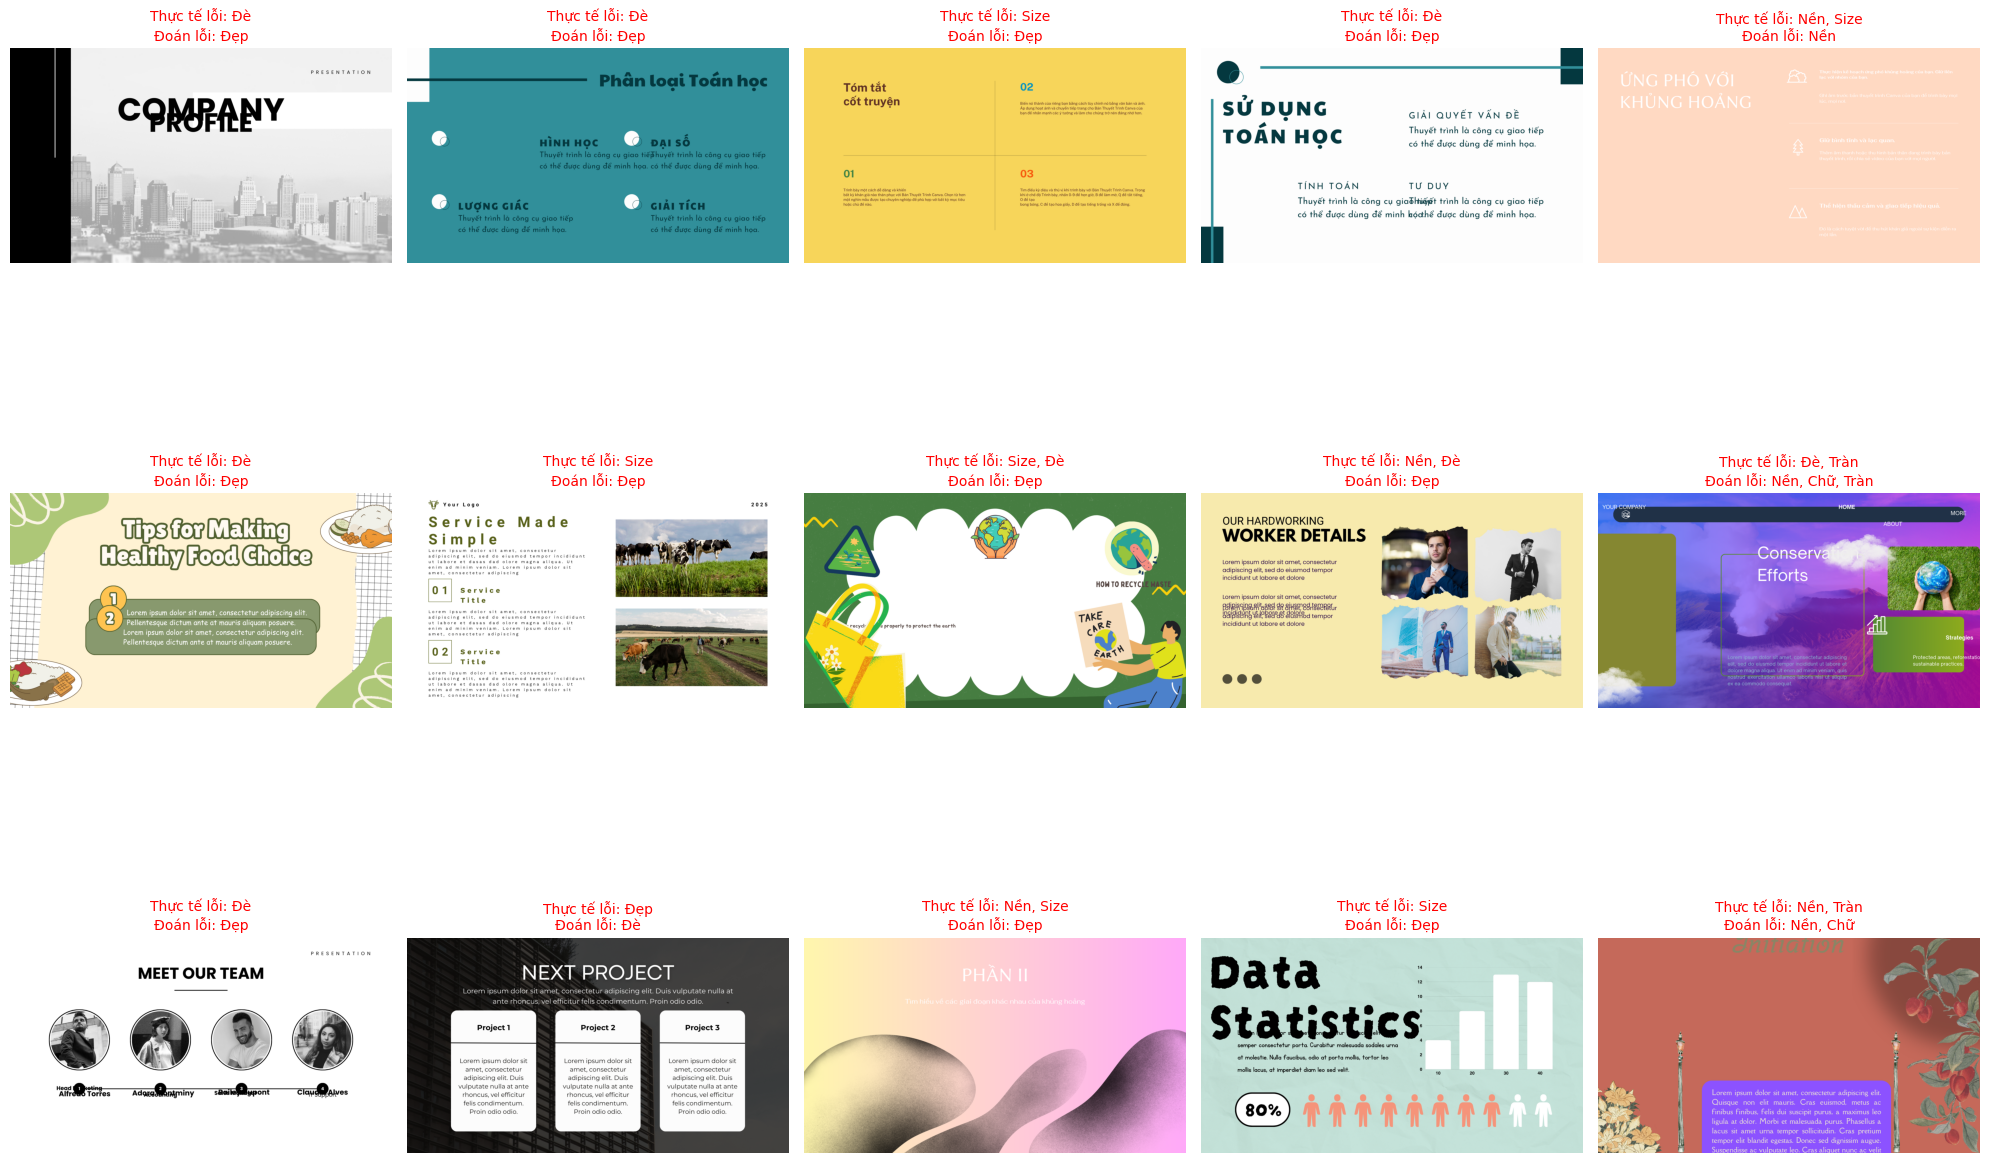

In [24]:
# Trực quan hóa Learning Curve (Loss và Pairwise Accuracy)
fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color=color)
ax1.plot(train_losses, label='Train Loss', color='tab:red', linestyle='--')
ax1.plot(val_losses, label='Val Loss', color='tab:orange')
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Pairwise Accuracy', color=color)
ax2.plot(val_acc_scores, label='Val Accuracy', color='tab:blue')
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='upper right')

plt.title('Learning Curves (Loss vs Pairwise Accuracy)')
fig.tight_layout()
plt.show()

In [25]:
# Không dùng cho bài toán Pairwise

Phân tích sai lệch tổ hợp: 100%|██████████| 411/411 [00:20<00:00, 20.16it/s]


THỰC TẾ                   | DỰ ĐOÁN                   | SỐ LƯỢNG
------------------------------------------------------------
Đè nhau                   | Đẹp                       | 30
Size                      | Đẹp                       | 17
Đẹp                       | Đè nhau                   | 17
Size + Đè nhau            | Đẹp                       | 9
Tràn                      | Đẹp                       | 7
Đẹp                       | Tràn                      | 5
Chữ + Đè nhau             | Đẹp                       | 5
Chữ + Đè nhau             | Chữ                       | 3
Nền + Đè nhau             | Đẹp                       | 3
Chữ + Tràn                | Đẹp                       | 3
Size + Tràn               | Đẹp                       | 3
Nền + Size                | Đẹp                       | 3
Đẹp                       | Size                      | 3
Đè nhau + Tràn            | Đẹp                       | 2
Nền + Đè nhau             | Nền                       | 2


### Biểu đồ phân bố và trực quan hóa kết quả đã hiển thị ở trên

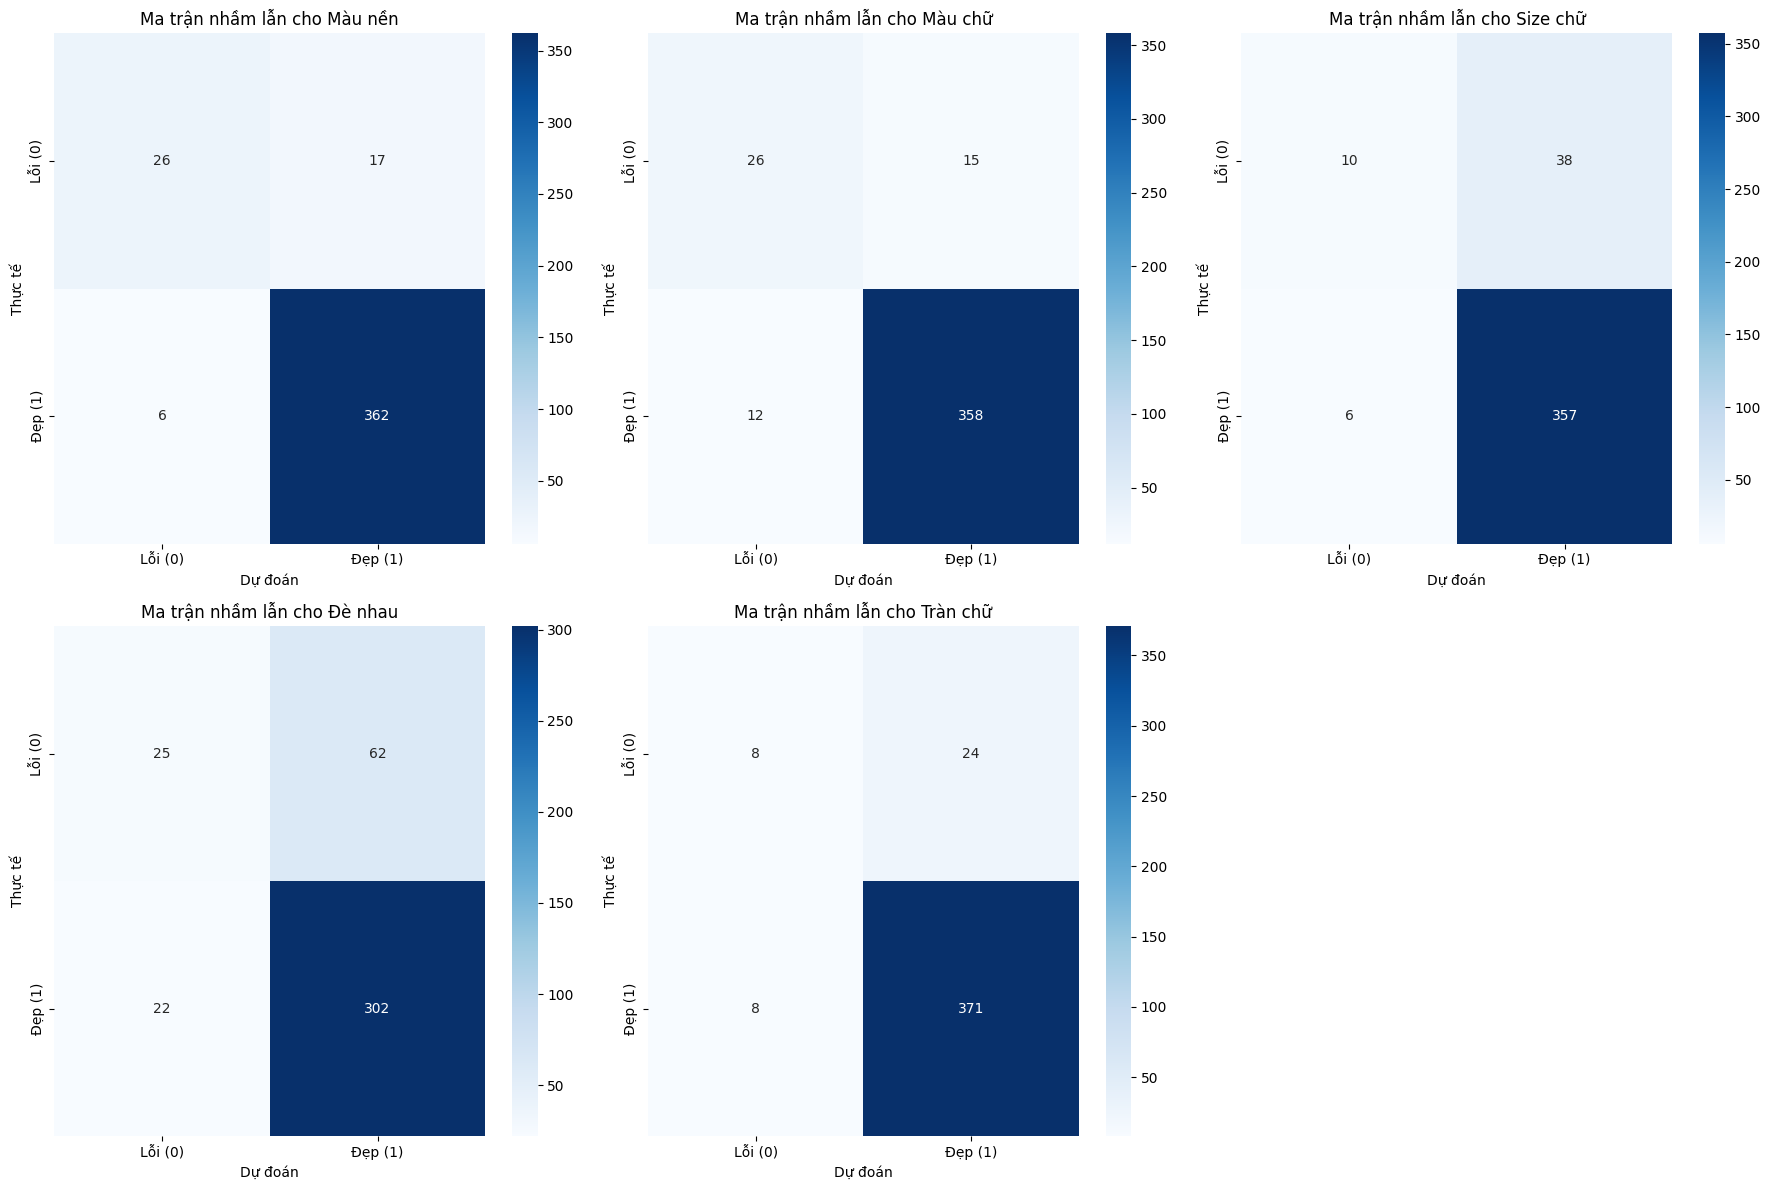

In [26]:
# Không dùng cho bài toán Pairwise

### Kết quả dự đoán thử nghiệm

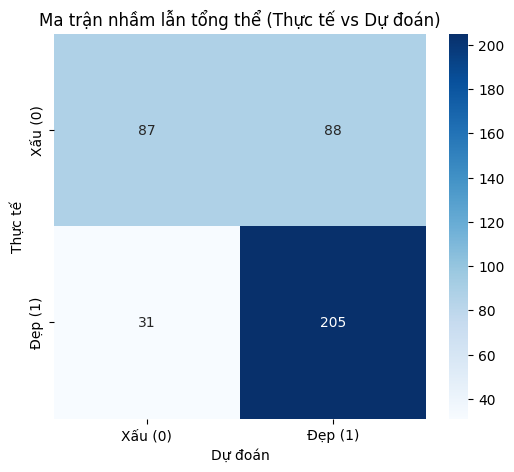

In [27]:
# Không dùng cho bài toán Pairwise

### Đánh giá mô hình với ảnh cụ thể

In [28]:
# Không dùng cho bài toán Pairwise

             BÁO CÁO PHÂN LOẠI TỔNG QUÁT (ĐẸP / XẤU)
              precision    recall  f1-score   support

         Xấu       0.74      0.50      0.59       175
         Đẹp       0.70      0.87      0.78       236

    accuracy                           0.71       411
   macro avg       0.72      0.68      0.68       411
weighted avg       0.72      0.71      0.70       411



Đánh giá với ảnh đầu vào.

Chúng ta sẽ thực hiện dự đoán thử nghiệm trên các ảnh mẫu để quan sát điểm số của slide Đẹp và slide Xấu.

In [29]:
import torch
from PIL import Image

# Hàm đánh giá điểm số của một slide ảnh bất kỳ
def predict_slide_score(model, image_path, transform, device):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(pixel_values=image_tensor).logits
        score = output.item()
    return score

# Thử nghiệm đánh giá ngẫu nhiên một cặp từ bộ Test
if len(test_data) > 0:
    test_good, test_bad = test_data[0]
    score_good = predict_slide_score(model, test_good, test_transforms, device)
    score_bad = predict_slide_score(model, test_bad, test_transforms, device)
    
    print(f"Đánh giá mẫu:")
    print(f"  - Slide Đẹp: {test_good}")
    print(f"    • Điểm số (Reward Score): {score_good:.4f}")
    print(f"  - Slide Xấu: {test_bad}")
    print(f"    • Điểm số (Reward Score): {score_bad:.4f}")
    print(f"  - Kết quả phân loại: {'ĐÚNG (Đẹp > Xấu)' if score_good > score_bad else 'SAI'}")

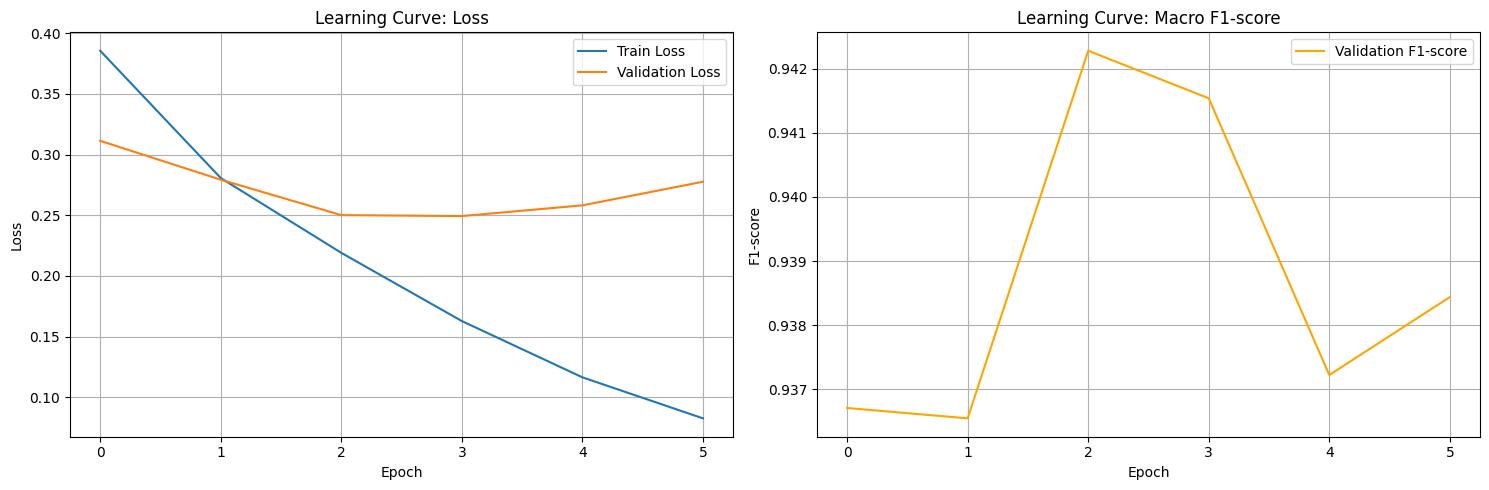

In [30]:
import matplotlib.pyplot as plt

# Vẽ hiển thị trực quan cặp slide và điểm số tương ứng
if len(test_data) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    
    img_good = Image.open(test_good)
    axes[0].imshow(img_good)
    axes[0].set_title(f"Slide Đẹp\nScore: {score_good:.4f}", color='green', fontsize=14)
    axes[0].axis('off')
    
    img_bad = Image.open(test_bad)
    axes[1].imshow(img_bad)
    axes[1].set_title(f"Slide Xấu\nScore: {score_bad:.4f}", color='red', fontsize=14)
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

In [31]:
# from google.colab import files

# # Tải file model đã lưu về máy tính cá nhân
# files.download('best_model_multilabel.pt')

In [32]:
# import torch
# from transformers import ViTForImageClassification

# def load_trained_model(model_path, device='cuda'):
#     """
#     Load mô hình ViT với cấu hình multi-label (5 nhãn)
#     """
#     model_name = 'WinKawaks/vit-small-patch16-224'

#     # 1. Khởi tạo lại cấu hình mô hình với 5 nhãn (tương ứng với lúc train)
#     model = ViTForImageClassification.from_pretrained(
#         model_name,
#         num_labels=5, # 5 tiêu chí: nền, chữ, size, bố cục, tràn
#         ignore_mismatched_sizes=True
#     )

#     # 2. Load trọng số (weights) từ file .pt đã lưu
#     # map_location giúp load model lên CPU nếu không có GPU
#     state_dict = torch.load(model_path, map_location=device)
#     model.load_state_dict(state_dict)

#     # 3. Chuyển mô hình sang thiết bị tính toán và chuyển sang chế độ eval
#     model.to(device)
#     model.eval()

#     print(f"--- Đã load thành công mô hình từ: {model_path} ---")
#     return model

# # --- CÁCH SỬ DỤNG ---
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model_path = '/kaggle/working/best_model_multilabel.pt' # Đường dẫn file của bạn


# #________________________________________________________________________________________
# model = load_trained_model(model_path, device)

# result, scores = predict_slide_quality(
#     image_path  = "/kaggle/input/datasets/trungnguyen2710t/test-slidegen/66.png",
#     model       = model,
#     transform   = test_transforms,
#     device      = device,
# )
# print(result)
# print("Xác suất (gần 1 = tốt, gần 0 = lỗi):", scores)

In [33]:
# # =============================================================================
# # 16. HÀM INFERENCE CHO ẢNH MỚI (với ngưỡng tối ưu)
# # =============================================================================
# def predict_slide_quality(image_path: str, model, transform, device,
#                            thresholds=None) -> tuple:
#     """
#     Dự đoán chất lượng slide từ đường dẫn ảnh.

#     Args:
#         image_path : đường dẫn file ảnh
#         model      : model đã load
#         transform  : test_transforms
#         device     : cpu hoặc cuda
#         thresholds : array ngưỡng riêng cho từng nhãn (mặc định 0.5 nếu None)

#     Returns:
#         result (str)      : mô tả kết quả
#         detailed (dict)   : xác suất từng tiêu chí (gần 1 = tốt, gần 0 = lỗi)
#     """
#     if thresholds is None:
#         thresholds = np.array([0.5] * 5)

#     label_names = ['Màu nền', 'Màu chữ', 'Size chữ', 'Đè nhau', 'Tràn nội dung']

#     image        = Image.open(image_path).convert("RGB")
#     pixel_values = transform(image).unsqueeze(0).to(device)

#     model.eval()
#     with torch.no_grad():
#         logits = model(pixel_values=pixel_values).logits
#         probs  = torch.sigmoid(logits).cpu().numpy()[0]

#     detected_errors = [
#         label_names[i] for i, p in enumerate(probs) if p < thresholds[i]
#     ]
#     detailed = {label_names[i]: f"{probs[i]:.3f}" for i in range(5)}

#     result = "Slide Đẹp (Đạt chuẩn)" if not detected_errors \
#              else f"Phát hiện lỗi: {', '.join(detected_errors)}"

#     return result, detailed


# def load_trained_model(model_path: str, device) -> ViTForImageClassification:
#     """Load model ViT multi-label đã train."""
#     model = ViTForImageClassification.from_pretrained(
#         'WinKawaks/vit-small-patch16-224',
#         num_labels=5,
#         ignore_mismatched_sizes=True
#     )
#     state_dict = torch.load(model_path, map_location=device)
#     model.load_state_dict(state_dict)
#     model.to(device)
#     model.eval()
#     print(f"Đã load model từ: {model_path}")
#     return model


# # --- VÍ DỤ SỬ DỤNG ---
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model  = load_trained_model('/kaggle/working/best_model_multilabel.pt', device)

# result, scores = predict_slide_quality(
#     image_path  = "/kaggle/input/datasets/trungnguyen2710t/test-slidegen/17.png",
#     model       = model,
#     transform   = test_transforms,
#     device      = device,
#     thresholds  = best_thresholds   # dùng ngưỡng tối ưu đã tính ở bước 12
# )
# print(result)
# print("Xác suất (gần 1 = tốt, gần 0 = lỗi):", scores)

In [34]:
# # =============================================================================
# # SLIDE MULTI-LABEL CLASSIFICATION - HOÀN CHỈNH & ĐÃ SỬA LỖI
# # Vector nhãn: [Màu nền, Màu chữ, Size chữ, Bố cục, Tràn chữ]
# # 1.0 = Tốt/Đạt, 0.0 = Lỗi/Xấu
# # =============================================================================

# import os
# import random
# import numpy as np
# import torch
# import torch.nn as nn
# from torch.utils.data import Dataset, DataLoader
# from torchvision import transforms
# from transformers import ViTForImageClassification
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import f1_score, classification_report
# from PIL import Image
# from tqdm import tqdm
# from collections import defaultdict
# import matplotlib.pyplot as plt
# import pandas as pd


# # =============================================================================
# # 1. CỐ ĐỊNH SEED (bao gồm cả worker seed cho DataLoader)
# # =============================================================================
# def seed_everything(seed: int):
#     random.seed(seed)
#     os.environ['PYTHONHASHSEED'] = str(seed)
#     np.random.seed(seed)
#     torch.manual_seed(seed)
#     torch.cuda.manual_seed(seed)
#     torch.cuda.manual_seed_all(seed)
#     torch.backends.cudnn.deterministic = True
#     torch.backends.cudnn.benchmark = False

# def seed_worker(worker_id):
#     """Dùng để đảm bảo reproducibility trong DataLoader workers."""
#     worker_seed = torch.initial_seed() % 2**32
#     np.random.seed(worker_seed)
#     random.seed(worker_seed)

# seed_everything(45)

# g = torch.Generator()
# g.manual_seed(45)  # FIX: dùng cùng seed với seed_everything


# # =============================================================================
# # 2. GÁN NHÃN ĐA NHIỆM - CHỈ MỘT HÀM DUY NHẤT (đọc từ đường dẫn)
# # =============================================================================
# # FIX: Gộp 2 hàm get_multi_label() và get_multi_label_from_path() thành 1
# # để tránh mâu thuẫn logic. Hàm cũ gán [0,0,0,0,0] cho xau_1/xau_2 là SAI.

# def get_label_from_path(full_path: str) -> list:
#     """
#     Gán vector nhãn [mau_nen, mau_chu, size_chu, bo_cuc, tran_chu]
#     dựa vào đường dẫn thực của file ảnh.
#     - 1.0 = Đạt (Tốt)
#     - 0.0 = Lỗi (Xấu)
#     """
#     label = [1.0, 1.0, 1.0, 1.0, 1.0]
#     path_lower = full_path.lower()

#     # Ảnh đẹp: giữ nguyên toàn 1
#     if '/dep/' in path_lower or path_lower.endswith('/dep'):
#         return label

#     # Lỗi màu nền
#     if 'mau_nen' in path_lower:
#         label[0] = 0.0

#     # Lỗi màu chữ
#     if 'mau_chu' in path_lower:
#         label[1] = 0.0

#     # Lỗi kích thước chữ
#     if 'size_chu' in path_lower or 'kich_thuoc' in path_lower:
#         label[2] = 0.0

#     # Lỗi bố cục / đè khối
#     if 'bo_cuc' in path_lower or 'de_nhau' in path_lower or 'de_len_nhau' in path_lower:
#         label[3] = 0.0

#     # Lỗi tràn nội dung
#     if 'tran_chu' in path_lower or 'tran_ra_ngoai' in path_lower:
#         label[4] = 0.0

#     return label


# # =============================================================================
# # 3. THU THẬP DỮ LIỆU
# # =============================================================================
# data_path = "/kaggle/input/datasets/trungnguyen2710t/slidegen/anh_slide"

# dep_list_dir   = [os.path.join(data_path, d, 'Dep')   for d in os.listdir(data_path)]
# xau_1_list_dir = [os.path.join(data_path, d, 'Xau_1') for d in os.listdir(data_path)]
# xau_2_list_dir = [os.path.join(data_path, d, 'Xau_2') for d in os.listdir(data_path)]

# all_data = []  # List of (image_path, label_vector)

# def collect_images(list_dirs: list):
#     for folder in list_dirs:
#         if not os.path.exists(folder):
#             continue
#         for root, _, files in os.walk(folder):
#             for f in files:
#                 if f.lower().endswith('.png'):
#                     full_path = os.path.join(root, f)
#                     label = get_label_from_path(full_path)
#                     all_data.append((full_path, label))

# collect_images(dep_list_dir)
# collect_images(xau_1_list_dir)
# collect_images(xau_2_list_dir)

# print(f"Tổng số ảnh đã gán nhãn: {len(all_data)}")


# # =============================================================================
# # 4. KIỂM TRA PHÂN PHỐI NHÃN VÀ TÍNH pos_weight
# # =============================================================================
# LABEL_NAMES = ['Màu nền', 'Màu chữ', 'Size chữ', 'Bố cục', 'Tràn chữ']

# labels_array = np.array([label for _, label in all_data])

# print("\nPHÂN PHỐI NHÃN (1 = Tốt, 0 = Lỗi):")
# for i, name in enumerate(LABEL_NAMES):
#     n_good = int(labels_array[:, i].sum())
#     n_bad  = len(labels_array) - n_good
#     print(f"  {name}: {n_good} tốt | {n_bad} lỗi  (tỉ lệ lỗi: {n_bad/len(labels_array)*100:.1f}%)")


# # =============================================================================
# # 5. CHIA DỮ LIỆU - FIX: dùng train_test_split thay vì chia theo số thứ tự
# # =============================================================================
# # FIX: Bỏ hoàn toàn logic chia theo slide_number vì không đảm bảo
# # phân phối nhãn đồng đều giữa train và test.

# train_data, test_data = train_test_split(
#     all_data,
#     test_size=0.2,
#     random_state=42,
#     shuffle=True
# )

# print(f"\nSố ảnh Train : {len(train_data)}")
# print(f"Số ảnh Test  : {len(test_data)}")


# # =============================================================================
# # 6. TRANSFORM - FIX: augmentation phù hợp hơn với slide (không crop mạnh)
# # =============================================================================
# IMAGE_MEAN = [0.485, 0.456, 0.406]
# IMAGE_STD  = [0.229, 0.224, 0.225]

# train_transforms = transforms.Compose([
#     # FIX: scale=(0.95, 1.0) thay vì (0.9, 1.0) để tránh cắt mất góc slide
#     # (quan trọng vì lỗi "tràn chữ" thường xuất hiện ở rìa)
#     transforms.RandomResizedCrop(224, scale=(0.95, 1.0)),
#     transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
#     transforms.RandomApply([
#         transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
#     ], p=0.2),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=IMAGE_MEAN, std=IMAGE_STD),
# ])

# test_transforms = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=IMAGE_MEAN, std=IMAGE_STD),
# ])


# # =============================================================================
# # 7. DATASET & DATALOADER
# # =============================================================================
# class SlideMultiLabelDataset(Dataset):
#     def __init__(self, data_list, transform=None):
#         self.data = data_list
#         self.transform = transform

#     def __len__(self):
#         return len(self.data)

#     def __getitem__(self, idx):
#         img_path, label = self.data[idx]
#         image = Image.open(img_path).convert("RGB")
#         if self.transform:
#             image = self.transform(image)
#         return image, torch.tensor(label, dtype=torch.float32)


# BATCH_SIZE = 128
# NUM_WORKERS = 2

# train_dataset = SlideMultiLabelDataset(train_data, transform=train_transforms)
# test_dataset  = SlideMultiLabelDataset(test_data,  transform=test_transforms)

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=BATCH_SIZE,
#     shuffle=True,
#     num_workers=NUM_WORKERS,
#     worker_init_fn=seed_worker,  # FIX: thêm vào để reproducibility
#     generator=g,                  # FIX: thêm vào để reproducibility
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=BATCH_SIZE,
#     shuffle=False,
#     num_workers=NUM_WORKERS,
# )


# # =============================================================================
# # 8. KHỞI TẠO MÔ HÌNH
# # =============================================================================
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print(f"\nDevice: {device}")

# MODEL_NAME = 'WinKawaks/vit-small-patch16-224'
# model = ViTForImageClassification.from_pretrained(
#     MODEL_NAME,
#     num_labels=5,
#     ignore_mismatched_sizes=True
# )
# model.to(device)


# # =============================================================================
# # 9. LOSS VỚI pos_weight - FIX: xử lý mất cân bằng nhãn
# # =============================================================================
# # Tính pos_weight dựa trên tập train
# train_labels_array = np.array([label for _, label in train_data])
# pos  = train_labels_array.sum(axis=0)                     # số ảnh "tốt" (label=1)
# neg  = len(train_labels_array) - pos                      # số ảnh "lỗi" (label=0)
# # pos_weight = neg/pos: nhãn càng ít positive thì weight càng cao
# pos_weight = torch.tensor(neg / (pos + 1e-6), dtype=torch.float32).to(device)

# print("\npos_weight cho từng nhãn (càng cao = nhãn càng mất cân bằng):")
# for i, name in enumerate(LABEL_NAMES):
#     print(f"  {name}: {pos_weight[i].item():.3f}")

# criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)


# # =============================================================================
# # 10. OPTIMIZER & SCHEDULER - FIX: thêm CosineAnnealingLR
# # =============================================================================
# NUM_EPOCHS    = 10
# LEARNING_RATE = 1e-4
# PATIENCE      = 3   # Early stopping

# optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)

# # FIX: Thêm scheduler để LR giảm dần theo cosine, hội tụ tốt hơn
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
# )


# # =============================================================================
# # 11. VÒNG LẶP HUẤN LUYỆN - FIX: thêm Early Stopping
# # =============================================================================
# train_losses      = []
# val_losses        = []
# val_f1_scores     = []
# best_f1           = 0.0
# epochs_no_improve = 0

# print("\n" + "="*60)
# print("BẮT ĐẦU HUẤN LUYỆN")
# print("="*60)

# for epoch in range(NUM_EPOCHS):

#     # ---- TRAIN ----
#     model.train()
#     running_loss = 0.0
#     pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")

#     for images, labels in pbar:
#         images, labels = images.to(device), labels.to(device)

#         optimizer.zero_grad()
#         outputs = model(pixel_values=images).logits
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()
#         pbar.set_postfix({'loss': f'{running_loss / (pbar.n + 1):.4f}'})

#     epoch_train_loss = running_loss / len(train_loader)
#     train_losses.append(epoch_train_loss)

#     # FIX: gọi scheduler sau mỗi epoch
#     scheduler.step()

#     # ---- VALIDATION ----
#     model.eval()
#     val_running_loss = 0.0
#     epoch_preds  = []
#     epoch_labels = []

#     with torch.no_grad():
#         for images, labels in tqdm(test_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"):
#             images, labels = images.to(device), labels.to(device)
#             outputs = model(pixel_values=images).logits
#             loss    = criterion(outputs, labels)
#             val_running_loss += loss.item()

#             preds = (torch.sigmoid(outputs) > 0.5).float()
#             epoch_preds.extend(preds.cpu().numpy())
#             epoch_labels.extend(labels.cpu().numpy())

#     epoch_val_loss = val_running_loss / len(test_loader)
#     val_losses.append(epoch_val_loss)

#     current_f1 = f1_score(epoch_labels, epoch_preds, average='macro', zero_division=0)
#     val_f1_scores.append(current_f1)

#     current_lr = scheduler.get_last_lr()[0]
#     print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}] "
#           f"Train Loss: {epoch_train_loss:.4f} | "
#           f"Val Loss: {epoch_val_loss:.4f} | "
#           f"Macro F1: {current_f1:.4f} | "
#           f"LR: {current_lr:.2e}")

#     # Lưu model tốt nhất
#     if current_f1 > best_f1:
#         best_f1 = current_f1
#         torch.save(model.state_dict(), "best_model_multilabel.pt")
#         print(f"  --> Saved best model (F1={best_f1:.4f})")
#         epochs_no_improve = 0
#     else:
#         epochs_no_improve += 1
#         print(f"  --> No improvement ({epochs_no_improve}/{PATIENCE})")
#         # FIX: Early stopping
#         if epochs_no_improve >= PATIENCE:
#             print(f"\nEarly stopping sau {epoch+1} epoch!")
#             break

# print(f"\nBest Macro F1: {best_f1:.4f}")


# # =============================================================================
# # 12. TÌM NGƯỠNG TỐI ƯU CHO TỪNG NHÃN - FIX: không dùng 0.5 cứng
# # =============================================================================
# print("\n" + "="*60)
# print("TÌM NGƯỠNG TỐI ƯU CHO TỪNG NHÃN")
# print("="*60)

# model.load_state_dict(torch.load("best_model_multilabel.pt", map_location=device))
# model.eval()

# all_probs  = []
# all_labels_np = []

# with torch.no_grad():
#     for images, labels in tqdm(test_loader, desc="Thu thập logits"):
#         images = images.to(device)
#         logits = model(pixel_values=images).logits
#         probs  = torch.sigmoid(logits).cpu().numpy()
#         all_probs.extend(probs)
#         all_labels_np.extend(labels.numpy())

# all_probs     = np.array(all_probs)      # (N, 5)
# all_labels_np = np.array(all_labels_np)  # (N, 5)

# # Tìm ngưỡng tốt nhất cho từng nhãn
# best_thresholds = []
# for i, name in enumerate(LABEL_NAMES):
#     best_thresh, best_f1_i = 0.5, 0.0
#     for thresh in np.arange(0.3, 0.71, 0.05):
#         preds_i = (all_probs[:, i] > thresh).astype(int)
#         f1_i    = f1_score(all_labels_np[:, i], preds_i, zero_division=0)
#         if f1_i > best_f1_i:
#             best_f1_i, best_thresh = f1_i, thresh
#     best_thresholds.append(best_thresh)
#     print(f"  {name}: best threshold = {best_thresh:.2f} | F1 = {best_f1_i:.4f}")

# best_thresholds = np.array(best_thresholds)


# # =============================================================================
# # 13. ĐÁNH GIÁ CUỐI CÙNG VỚI NGƯỠNG TỐI ƯU
# # =============================================================================
# print("\n" + "="*60)
# print("ĐÁNH GIÁ CUỐI CÙNG (với ngưỡng tối ưu)")
# print("="*60)

# final_preds = (all_probs > best_thresholds).astype(float)

# print(classification_report(
#     all_labels_np, final_preds,
#     target_names=LABEL_NAMES,
#     zero_division=0
# ))

# # Accuracy từng nhãn
# y_true = all_labels_np
# y_pred = final_preds

# correct_per_label  = np.sum(y_true == y_pred, axis=0)
# total_images       = len(y_true)
# wrong_per_label    = total_images - correct_per_label
# accuracy_per_label = correct_per_label / total_images

# df_result = pd.DataFrame({
#     'Đoán đúng': correct_per_label,
#     'Đoán sai' : wrong_per_label,
#     'Accuracy' : [f"{acc*100:.2f}%" for acc in accuracy_per_label],
#     'Tổng ảnh' : [total_images] * 5
# }, index=LABEL_NAMES)

# print("\nBẢNG ĐÁNH GIÁ CHI TIẾT THEO TIÊU CHÍ:")
# print(df_result)

# perfect_match = np.all(y_true == y_pred, axis=1)
# print(f"\nĐộ chính xác tuyệt đối (đúng cả 5/5): {np.sum(perfect_match)/total_images*100:.2f}%")


# # =============================================================================
# # 14. THỐNG KÊ LỖI THEO TỔ HỢP
# # =============================================================================
# print("\n" + "="*60)
# print("THỐNG KÊ SAI LỆ THEO TỔ HỢP (Thực tế → Dự đoán)")
# print("="*60)

# short_names = ['Nền', 'Chữ', 'Size', 'Bố cục', 'Tràn']
# error_stats = defaultdict(int)

# for i in range(len(y_true)):
#     if not np.array_equal(y_pred[i], y_true[i]):
#         t_errors = [short_names[j] for j in range(5) if y_true[i][j] == 0.0]
#         p_errors = [short_names[j] for j in range(5) if y_pred[i][j] == 0.0]
#         t_str = " + ".join(t_errors) if t_errors else "Đẹp"
#         p_str = " + ".join(p_errors) if p_errors else "Đẹp"
#         error_stats[f"{t_str}  -->  {p_str}"] += 1

# sorted_stats = sorted(error_stats.items(), key=lambda x: x[1], reverse=True)
# print(f"{'THỰC TẾ':<30} | {'DỰ ĐOÁN':<30} | SỐ LƯỢNG")
# print("-" * 70)
# for key, count in sorted_stats[:20]:  # chỉ in top 20
#     t_part, p_part = key.split("  -->  ")
#     print(f"{t_part:<30} | {p_part:<30} | {count}")


# # =============================================================================
# # 15. HIỂN THỊ ẢNH SAI
# # =============================================================================
# misclassified = []
# for i in range(len(test_data)):
#     img_path, true_label = test_data[i]
#     if not np.array_equal(y_pred[i], np.array(true_label)):
#         true_errors = [short_names[j] for j in range(5) if true_label[j] == 0.0]
#         pred_errors = [short_names[j] for j in range(5) if y_pred[i][j] == 0.0]
#         misclassified.append({
#             "path"      : img_path,
#             "true_label": " + ".join(true_errors) if true_errors else "Đẹp",
#             "pred_label": " + ".join(pred_errors) if pred_errors else "Đẹp",
#         })

# print(f"\nTổng ảnh đoán sai ít nhất 1 tiêu chí: {len(misclassified)}")

# if misclassified:
#     num_show   = min(15, len(misclassified))
#     sample_err = random.sample(misclassified, num_show)
#     ncols = 5
#     nrows = (num_show + ncols - 1) // ncols

#     fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 5 * nrows))
#     axes = axes.flatten()

#     for i, err in enumerate(sample_err):
#         img = Image.open(err["path"])
#         axes[i].imshow(img)
#         color = 'red' if err['true_label'] != err['pred_label'] else 'orange'
#         axes[i].set_title(
#             f"Thực tế: {err['true_label']}\nĐoán: {err['pred_label']}",
#             fontsize=9, color=color
#         )
#         axes[i].axis('off')

#     for j in range(i + 1, len(axes)):
#         axes[j].axis('off')

#     plt.tight_layout()
#     plt.savefig("misclassified_samples.png", dpi=150, bbox_inches='tight')
#     plt.show()


# # =============================================================================
# # 16. HÀM INFERENCE CHO ẢNH MỚI (với ngưỡng tối ưu)
# # =============================================================================
# def predict_slide_quality(image_path: str, model, transform, device,
#                            thresholds=None) -> tuple:
#     """
#     Dự đoán chất lượng slide từ đường dẫn ảnh.

#     Args:
#         image_path : đường dẫn file ảnh
#         model      : model đã load
#         transform  : test_transforms
#         device     : cpu hoặc cuda
#         thresholds : array ngưỡng riêng cho từng nhãn (mặc định 0.5 nếu None)

#     Returns:
#         result (str)      : mô tả kết quả
#         detailed (dict)   : xác suất từng tiêu chí (gần 1 = tốt, gần 0 = lỗi)
#     """
#     if thresholds is None:
#         thresholds = np.array([0.5] * 5)

#     label_names = ['Màu nền', 'Màu chữ', 'Size chữ', 'Bố cục', 'Tràn nội dung']

#     image        = Image.open(image_path).convert("RGB")
#     pixel_values = transform(image).unsqueeze(0).to(device)

#     model.eval()
#     with torch.no_grad():
#         logits = model(pixel_values=pixel_values).logits
#         probs  = torch.sigmoid(logits).cpu().numpy()[0]

#     detected_errors = [
#         label_names[i] for i, p in enumerate(probs) if p < thresholds[i]
#     ]
#     detailed = {label_names[i]: f"{probs[i]:.3f}" for i in range(5)}

#     result = "Slide Đẹp (Đạt chuẩn)" if not detected_errors \
#              else f"Phát hiện lỗi: {', '.join(detected_errors)}"

#     return result, detailed


# def load_trained_model(model_path: str, device) -> ViTForImageClassification:
#     """Load model ViT multi-label đã train."""
#     model = ViTForImageClassification.from_pretrained(
#         'WinKawaks/vit-small-patch16-224',
#         num_labels=5,
#         ignore_mismatched_sizes=True
#     )
#     state_dict = torch.load(model_path, map_location=device)
#     model.load_state_dict(state_dict)
#     model.to(device)
#     model.eval()
#     print(f"Đã load model từ: {model_path}")
#     return model


# # --- VÍ DỤ SỬ DỤNG ---
# # device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# # model  = load_trained_model('/kaggle/working/best_model_multilabel.pt', device)
# #
# # result, scores = predict_slide_quality(
# #     image_path  = "/kaggle/input/.../test_slide.png",
# #     model       = model,
# #     transform   = test_transforms,
# #     device      = device,
# #     thresholds  = best_thresholds   # dùng ngưỡng tối ưu đã tính ở bước 12
# # )
# # print(result)
# # print("Xác suất (gần 1 = tốt, gần 0 = lỗi):", scores)

### Trực quan hóa Learning Curve (Loss và F1-score)